In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
import math


In [2]:
class Constantes():
    def __init__(self,pixscale, filt, v3i):
        self.pixscale = pixscale # arcsec
        self.filt     = filt
        self.v3i      = v3i      #header[1]['V3I_YANG']  # 4.83544897 #4QPM rotation
        if filt == 'F1065C': self.lam = 10.65e-6 #central wavelenght for each filter
        if filt == 'F1140C': self.lam = 11.4e-6
        if filt == 'F1550C': self.lam = 15.5e-6
        if filt == 'F2300C': self.lam = 23.0e-6
    def addition(xdim, ydim, dr, npsf):
        self.dr   = dr
        self.npsf = npsf
        self.xdim = xdim
        self.ydim = ydim



def coro_attenuation_measure(psf_coro, plan_sepX, plan_sepY):

    res_max_psf = []
    res_sum_psf = []
    res_sum_img = []
    mask_map    = np.ndarray([cst.npsf,cst.ydim,cst.xdim])*0.
    Y, X = np.ogrid[:cst.xdim, :cst.ydim] #grid for mask
    for i in range(cst.npsf):
        res_max_psf.append(np.max(psf_coro[i,:,:]))
        cpsfx = round(plan_sepX[i]/cst.pixscale + 0.5) #centre de la PSF
        cpsfy = round(plan_sepY[i]/cst.pixscale + 0.5) #centre de la PSF    
        mask = np.sqrt((X - cst.xdim//2 -cpsfx +0.5)**2 + (Y - cst.ydim//2 -cpsfy +0.5)**2)
        mask_map[i,:,:] = (mask <= cst.dr)
        res_sum_psf.append(np.nansum(psf_coro[i,:,:]*mask_map[i,:,:]))
        res_sum_img.append(np.nansum(psf_coro[i,:,:]))
    return res_max_psf, res_sum_psf, res_sum_img, mask_map 

    


def coro_attenuation_4q(path_sim, path_save, filename, filt):
    
    #NW
    filename_1  = 'MIRI_2024_attenuation_NW_'+filename+'.fits'
    file_sepx_1 = 'MIRI_2024_attenuation_NW_'+filename+'_SEP-X.fits'
    file_sepy_1 = 'MIRI_2024_attenuation_NW_'+filename+'_SEP-Y.fits'
    #SW
    filename_2  = 'MIRI_2024_attenuation_SW_'+filename+'.fits'
    file_sepx_2 = 'MIRI_2024_attenuation_SW_'+filename+'_SEP-X.fits'
    file_sepy_2 = 'MIRI_2024_attenuation_SW_'+filename+'_SEP-Y.fits'
    #NE
    filename_3  = 'MIRI_2024_attenuation_NE_'+filename+'.fits'
    file_sepx_3 = 'MIRI_2024_attenuation_NE_'+filename+'_SEP-X.fits'
    file_sepy_3 = 'MIRI_2024_attenuation_NE_'+filename+'_SEP-Y.fits'
    #SE
    filename_4  = 'MIRI_2024_attenuation_SE_'+filename+'.fits'
    file_sepx_4 = 'MIRI_2024_attenuation_SE_'+filename+'_SEP-X.fits'
    file_sepy_4 = 'MIRI_2024_attenuation_SE_'+filename+'_SEP-Y.fits'
    
    #initialisation
    file  = fits.open(path_sim+filename_1)
    fileX = fits.open(path_sim+file_sepx_1)
    fileY = fits.open(path_sim+file_sepy_1)
    psf_coro = file[0].data
    cst.xdim = np.shape(psf_coro)[-1] 
    cst.ydim = np.shape(psf_coro)[-2]
    cst.npsf = np.shape(psf_coro)[0]
    print('initialization : npsf='+str(cst.npsf)+' xdim='+str(cst.xdim)+' ydim='+str(cst.ydim))
    plan_sepX = np.zeros(cst.npsf*4, dtype='float32')
    plan_sepY = np.zeros(cst.npsf*4, dtype='float32')
    max_psf   = np.zeros(cst.npsf*4, dtype='float32')
    sum_psf   = np.zeros(cst.npsf*4, dtype='float32')
    sum_img   = np.zeros(cst.npsf*4, dtype='float32')
    file.close()
    fileX.close()
    fileY.close()
    
    #NW
    file  = fits.open(path_sim+filename_1)
    fileX = fits.open(path_sim+file_sepx_1)
    fileY = fits.open(path_sim+file_sepy_1)
    psf_coro = file[0].data
    plan_sepX[:cst.npsf] = fileX[0].data
    plan_sepY[:cst.npsf] = fileY[0].data
    file.close()
    fileX.close()
    fileY.close()

    max_psf[0:cst.npsf], sum_psf[0:cst.npsf], sum_img[0:cst.npsf], mask_map = coro_attenuation_measure(psf_coro, plan_sepX, plan_sepY)
    imp.save_fits(mask_map, path_save+filt+'_mask_map_NW.fits')

    #SW
    file  = fits.open(path_sim+filename_2)
    fileX = fits.open(path_sim+file_sepx_2)
    fileY = fits.open(path_sim+file_sepy_2)  
    psf_coro = file[0].data
    plan_sepX[:cst.npsf] = fileX[0].data
    plan_sepY[:cst.npsf] = fileY[0].data
    file.close()
    fileX.close()
    fileY.close()

    max_psf[cst.npsf:2*cst.npsf], sum_psf[cst.npsf:2*cst.npsf], sum_img[cst.npsf:2*cst.npsf], mask_map = coro_attenuation_measure(psf_coro, plan_sepX, plan_sepY)
    imp.save_fits(mask_map, path_save+filt+'_mask_map_SW.fits')

    #NE
    file  = fits.open(path_sim+filename_3)
    fileX = fits.open(path_sim+file_sepx_3)
    fileY = fits.open(path_sim+file_sepy_3)
    psf_coro = file[0].data
    plan_sepX[:cst.npsf] = fileX[0].data
    plan_sepY[:cst.npsf] = fileY[0].data
    file.close()
    fileX.close()
    fileY.close()

    max_psf[2*cst.npsf:3*cst.npsf], sum_psf[2*cst.npsf:3*cst.npsf], sum_img[2*cst.npsf:3*cst.npsf], mask_map = coro_attenuation_measure(psf_coro, plan_sepX, plan_sepY)
    imp.save_fits(mask_map, path_save+filt+'_mask_map_NE.fits')
    
    #SE
    file  = fits.open(path_sim+filename_4)
    fileX = fits.open(path_sim+file_sepx_4)
    fileY = fits.open(path_sim+file_sepy_4)
    psf_coro = file[0].data
    plan_sepX[:cst.npsf] = fileX[0].data
    plan_sepY[:cst.npsf] = fileY[0].data
    file.close()
    fileX.close()
    fileY.close()

    max_psf[3*cst.npsf:4*cst.npsf], sum_psf[3*cst.npsf:4*cst.npsf], sum_img[3*cst.npsf:4*cst.npsf], mask_map = coro_attenuation_measure(psf_coro, plan_sepX, plan_sepY)
    imp.save_fits(mask_map, path_save+filt+'_mask_map_SE.fits')
    
    
    
    f_co = sum_img/sum_psf    

    max_psf /= np.max(max_psf)
    sum_psf /= np.max(sum_psf)
    return f_co, max_psf, sum_psf, plan_sepX, plan_sepY




def coro_attenuation_plot(plan_sepX, max_psf, sum_psf, path_save):



    fig1,[sub1,sub2] = plt.subplots(nrows=1,ncols=2,figsize=(25,15))
    plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
    for i in range(50):
        sub1.plot(plan_sepX[i*50:(i+1)*50],max_psf[i*50:(i+1)*50],'o')
        sub2.plot(plan_sepX[i*50:(i+1)*50],sum_psf[i*50:(i+1)*50],'o')
    sub1.legend()
    sub2.legend()
    sub1.set_title('Max')
    sub2.set_title('Total')
    sub1.set_ylabel('Flux')
    sub1.set_xlabel('Separation [arcsec]')
    sub2.set_xlabel('Separation [arcsec]')
    fig1.savefig(path_save+cst.filt+'_transmission_cut_max_and_sum.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)


    imp.save_fits(sum_psf,path_save+cst.filt+'_sum_psf.fits')


    transmi_max = np.zeros([cst.ydim,cst.xdim])


    for i in range(round(np.sqrt(cst.npsf))):
        for j in range(round(np.sqrt(cst.npsf))):
            transmi_max[cst.ydim//2+i,cst.xdim//2+j] = max_psf[i*round(np.sqrt(cst.npsf))+j]
            transmi_max[cst.ydim//2+i,cst.xdim//2-j-1] = max_psf[i*round(np.sqrt(cst.npsf))+j+1*cst.npsf]
            transmi_max[cst.ydim//2-i-1,cst.xdim//2+j] = max_psf[i*round(np.sqrt(cst.npsf))+j+2*cst.npsf]
            transmi_max[cst.ydim//2-i-1,cst.xdim//2-j-1] = max_psf[i*round(np.sqrt(cst.npsf))+j+3*cst.npsf]

    transmi_sum = np.zeros([cst.ydim,cst.xdim])


    for i in range(round(np.sqrt(cst.npsf))):
        for j in range(round(np.sqrt(cst.npsf))):
            transmi_sum[cst.ydim//2+i,cst.xdim//2+j] = sum_psf[i*round(np.sqrt(cst.npsf))+j]
            transmi_sum[cst.ydim//2+i,cst.xdim//2-j-1] = sum_psf[i*round(np.sqrt(cst.npsf))+j+1*cst.npsf]
            transmi_sum[cst.ydim//2-i-1,cst.xdim//2+j] = sum_psf[i*round(np.sqrt(cst.npsf))+j+2*cst.npsf]
            transmi_sum[cst.ydim//2-i-1,cst.xdim//2-j-1] = sum_psf[i*round(np.sqrt(cst.npsf))+j+3*cst.npsf]

    #### difference between both method       
    imp.save_fits(transmi_sum-transmi_max,path_save+cst.filt+'_diff_transmission_sum-max.fits')
    scale=[(cst.xdim/2.-50)*cst.pixscale,-1*(cst.xdim/2.-50)*cst.pixscale,-1*(cst.ydim/2.-50)*cst.pixscale,(cst.ydim/2.-50)*cst.pixscale]
    fig1 = plt.figure(figsize=(8,8))
    tmp = plt.imshow((transmi_sum-transmi_max)[cst.ydim//2-50:cst.ydim//2+50,cst.xdim//2-50:cst.xdim//2+50],origin='lower',cmap='seismic',interpolation='none',vmin=-0.10,vmax=0.10,extent=scale)
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('Transmission difference',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    plt.show()
    fig1.savefig(path_save+cst.filt+'_diff_transmission_sum-max.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)


    ### rotation of the transmission map to fit with the real image
    #scale=[(xdim/2.-40)*pixscale,-1*(xdim/2.-40)*pixscale,-1*(ydim/2.-40)*pixscale,(ydim/2.-40)*pixscale]        
    transmi_max = ndimage.rotate(transmi_max, (cst.v3i), reshape=False)        
    transmi_max[transmi_max <= 0.01] = math.nan
    transmi_max[transmi_max >= 1.01] = math.nan
    transmi_max[transmi_max >= 1.0]  = 1.0
    plt.figure(figsize=(8,8))
    plt.imshow(transmi_max[cst.ydim//2-50:cst.ydim//2+50,cst.xdim//2-50:cst.xdim//2+50],origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
    plt.show()


    transmi_sum = ndimage.rotate(transmi_sum, (cst.v3i), reshape=False)        
    transmi_sum[transmi_sum <= 0.01] = math.nan
    transmi_sum[transmi_sum >= 1.01] = math.nan
    transmi_sum[transmi_sum >= 1.0]  = 1.0
    plt.figure(figsize=(8,8))
    plt.imshow(transmi_sum[cst.ydim//2-50:cst.ydim//2+50,cst.xdim//2-50:cst.xdim//2+50],origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
    plt.show()


    imp.save_fits(transmi_sum,path_save+cst.filt+'_transmi_sum.fits')
    imp.save_fits(transmi_max,path_save+cst.filt+'_transmi_max.fits')






        
        


initialization : npsf=2500 xdim=200 ydim=200


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


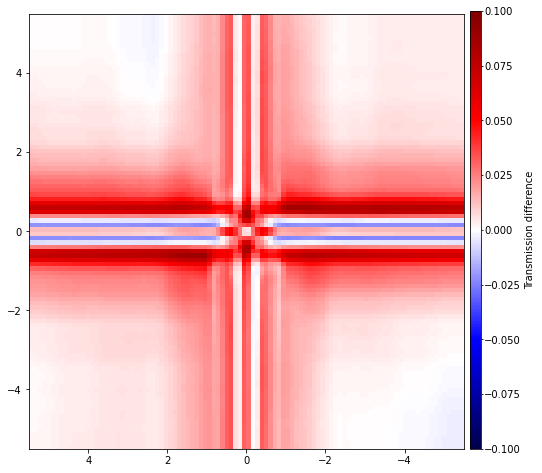

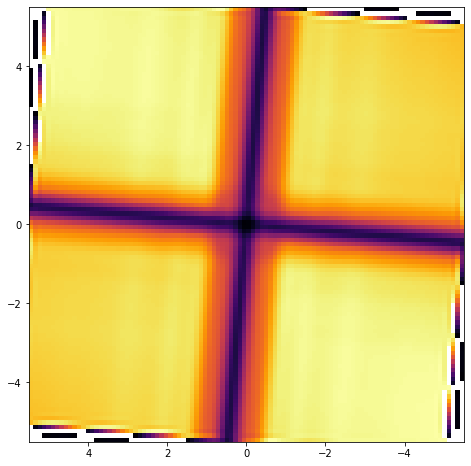

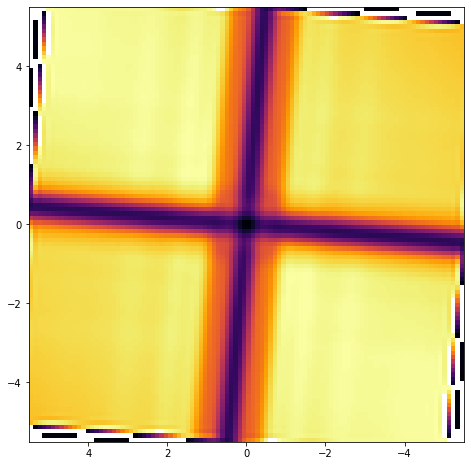

In [3]:
### F1550C avec le code d'Anthony

path_sim  = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/planet_attenuation/'
path_save = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
filename  = 'attenuation_F1550C'
filt      = 'F1550C'
#constant
coef_dr   = 1.5
cst = Constantes(0.110, 'F1550C', 4.83544897)
cst.dr = coef_dr*cst.lam/6.5*180.*3600./np.pi/cst.pixscale # taille en pixel de COEF_DR lambda/D


out_f_co, out_max_psf, out_sum_psf, out_plan_sepX, out_plan_sepY = coro_attenuation_4q(path_sim, path_save, filename, filt)
coro_attenuation_plot(out_plan_sepX, out_max_psf, out_sum_psf, path_save)

initialization : npsf=2500 xdim=200 ydim=200


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


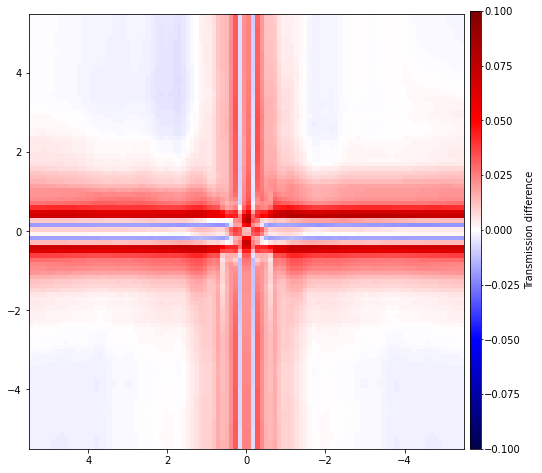

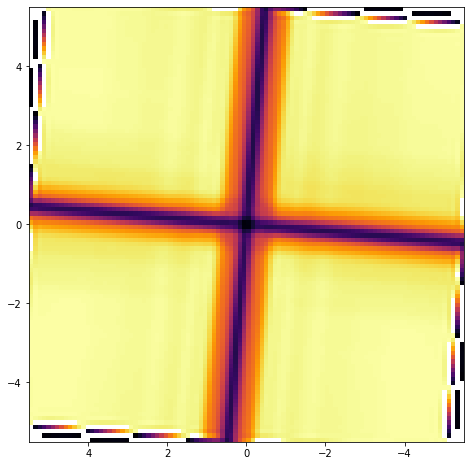

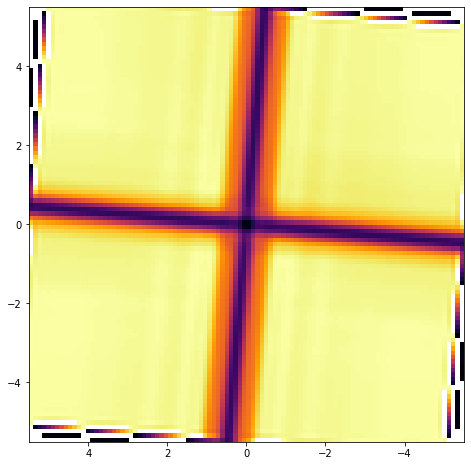

In [5]:
### F1140C avec le code d'Anthony

path_sim  = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/planet_attenuation/'
path_save = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
filename  = 'HD181327_F1140C'
filt      = 'F1140C'
#constant
coef_dr   = 1.5
cst = Constantes(0.110, 'F1140C', 4.83544897)
cst.dr = coef_dr*cst.lam/6.5*180.*3600./np.pi/cst.pixscale # taille en pixel de COEF_DR lambda/D


out_f_co, out_max_psf, out_sum_psf, out_plan_sepX, out_plan_sepY = coro_attenuation_4q(path_sim, path_save, filename, filt)
coro_attenuation_plot(out_plan_sepX, out_max_psf, out_sum_psf, path_save)

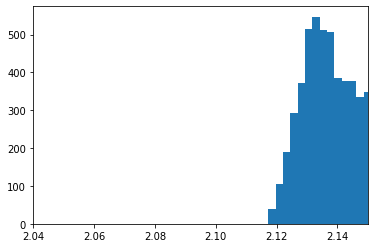

2.1517186

In [6]:
plt.hist(out_f_co[:], 700)
plt.xlim([2.04,2.15])
plt.show()
np.median(out_f_co)

In [7]:
#facteur de correction d'ouverture obtenu avec STPSF : flux in 1.5L/D : 0.25375 ; flux in the image : 0.57283 : 0.57283/0.25375 = 2.25745 a F1140C

#Pour F1550C avec le code d'Anthony :

path_sim = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/planet_attenuation/'

psf   = fits.open(path_sim+"MIRI_2024_corono_for_contrast_attenuation_F1550C.fits")[0].data
posx  = fits.open(path_sim+"MIRI_2024_corono_for_contrast_attenuation_F1550C_SEP-X.fits")[0].data
posy  = fits.open(path_sim+"MIRI_2024_corono_for_contrast_attenuation_F1550C_SEP-Y.fits")[0].data



V3i_1   = 4.83544897 #header_tar_1[1]['V3I_YANG']  # 4.83544897 #4QPM rotation
ydim = 200 #np.shape(image)[-2]
xdim = 200 #np.shape(image)[-1]
pixscale = 0.110 # arcsec

lam = 15.5e-6
dr = 1.5*lam/6.5*180.*3600./np.pi/pixscale # taille en pixel de 1.5 lambda/D

Y, X = np.ogrid[:ydim, :xdim]

cpsfx = round(posx[1]/pixscale + 0.5) #centre de la PSF
cpsfy = round(posy[1]/pixscale + 0.5) #centre de la PSF 
mask = np.sqrt((X - xdim//2 -cpsfx +0.5)**2 + (Y - ydim//2 -cpsfy +0.5)**2)
mask = mask <= dr


print("F1550C : ")
print("flux dans un PO de 1.5L/D de rayon :",np.nansum(mask*psf[1]))
print("Flux dans toute l'image :",np.nansum(psf[1]))
print("facteur de correction d'ouverture : ",np.nansum(psf[1])/np.nansum(mask*psf[1]))



psf   = fits.open(path_sim+"MIRI_2024_corono_for_contrast_HD181327_F1140C.fits")[0].data
posx  = fits.open(path_sim+"MIRI_2024_corono_for_contrast_HD181327_F1140C_SEP-X.fits")[0].data
posy  = fits.open(path_sim+"MIRI_2024_corono_for_contrast_HD181327_F1140C_SEP-Y.fits")[0].data
lam = 11.4e-6
dr = 1.5*lam/6.5*180.*3600./np.pi/pixscale # taille en pixel de 1.5 lambda/D
Y, X = np.ogrid[:ydim, :xdim]

cpsfx = round(posx[1]/pixscale + 0.5) #centre de la PSF
cpsfy = round(posy[1]/pixscale + 0.5) #centre de la PSF 

mask = np.sqrt((X - xdim//2 -cpsfx +0.5)**2 + (Y - ydim//2 -cpsfy +0.5)**2)
mask = mask <= dr


print("F1140C :")
print("flux dans un PO de 1.5L/D de rayon :",np.nansum(mask*psf[1]))
print("Flux dans toute l'image :",np.nansum(psf[1]))
print("facteur de correction d'ouverture : ",np.nansum(psf[1])/np.nansum(mask*psf[1]))


F1550C : 
flux dans un PO de 1.5L/D de rayon : 0.3983975744072594
Flux dans toute l'image : 0.8258541935967029
facteur de correction d'ouverture :  2.072939813515226
F1140C :
flux dans un PO de 1.5L/D de rayon : 0.3605667846694793
Flux dans toute l'image : 0.7663140732780076
facteur de correction d'ouverture :  2.1253041207898966
